In [1]:
#imports
import numpy as np
import pandas as pd
import astropy.units as u
import astropy.constants as const
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
import math
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models

In [2]:
#V5589 Sgr - can't tell where the radio peak is
#U Sco - can't tell where the radio peak is
#V1534 Sco - can't tell where the radio peak is
#V1535 Sco - maybe we have the radio peak???

info = (
    ["V392 Per", 3, 5.6, 5.226, .262, 32, 81.9, 4100],
    ["V407 Cyg", 5.9, 7.1, 17.77, 0.901,  102.6, 43*365.25*24, 3200],
    ["V1535 Sco", 13.9, 9.7, 4.123, .208 , 2.663, 39.6*24, 4700],
    ["V1534 Sco", 5.6, 11.6, 13.3, .665 ,14.65, 520*24, 4100],
    ['V723 Cas', 263, 7.1, 13.5, 1.125 , 1697, 16.6, 1750],
    ['V5589 Sgr', 4.5, 8.8, 3.423, .173, 62.3, 38.2, 4800],
    ['RS Oph', 2.77,4.5, 67.597, 3.381, 9.99, 453.6*24,3700],
    ['U Sco', 1.89, 7.769, 0.115, 0.029, 32.53, 29.5, 5000],
    ['V745 Sco',2.5,8.66,8.93,0.45,25.6, 136.5*24,4450],
    ['V3890 Sgr',6.4,8.1,51.11,2.56,11.2,747.6*24,4200],
    ['V1370 Aql',15,7.7,14.2,0,142,1.9581*24,2200] #Smax is >14.2 no error given 

)

df = pd.DataFrame(info, columns = ['Nova (names)', 't2 visual (when the optical declined by 2 mag)', 'Vpeak (optical peak apparent mag)', 
                                   'flux max (Smax)','Smax error', 'day when flux max (tmax)', 'orbital period (hours)', 'velocity (km/s)'])

#RS Oph info from https://academic.oup.com/mnras/article/515/3/4655/6649834, everything else is from Bella's overleaf

df

,Nova (names),t2 visual (when the optical declined by 2 mag),Vpeak (optical peak apparent mag),flux max (Smax),Smax error,day when flux max (tmax),orbital period (hours),velocity (km/s)
0,V392 Per,3.00,5.600,5.226,0.262,32.000,81.9000,4100
1,V407 Cyg,5.90,7.100,17.770,0.901,102.600,376938.0000,3200
2,V1535 Sco,13.90,9.700,4.123,0.208,2.663,950.4000,4700
3,V1534 Sco,5.60,11.600,13.300,0.665,14.650,12480.0000,4100
4,V723 Cas,263.00,7.100,13.500,1.125,1697.000,16.6000,1750
5,V5589 Sgr,4.50,8.800,3.423,0.173,62.300,38.2000,4800
6,RS Oph,2.77,4.500,67.597,3.381,9.990,10886.4000,3700
7,U Sco,1.89,7.769,0.115,0.029,32.530,29.5000,5000
8,V745 Sco,2.50,8.660,8.930,0.450,25.600,3276.0000,4450
9,V3890 Sgr,6.40,8.100,51.110,2.560,11.200,17942.4000,4200


## t2 vs tmax

Plot showing the t2 (x-axis)(time to delcine by 2 mag in the optical) vs the day that the radio lightcurve is on the peak (y axis) 

(log log for both axis) (for 5GHz frequency band)


In [3]:
t2 = df['t2 visual (when the optical declined by 2 mag)']

tmax = df['day when flux max (tmax)']

names = df["Nova (names)"]

In [4]:
#PL =  PowerLaw1D(amplitude = tmax[0], x_0= t2[0], alpha= 13.3) 
#fit = fitting.LevMarLSQFitter(calc_uncertainties=True)


#Fit the data w/o weights
#fit_model = fit(PL, t2, tmax)


#weight is 1/error^2
#x_weight = 1/ (np.power(x_err,2))  

# fit the data using the uncertainties as weights
#fit_model_weights = fit(PL, t2, tmax, weights=None)

#fit_model_weights

In [4]:
coefficients = np.polyfit(t2, tmax, 1)
poly = np.poly1d(coefficients)

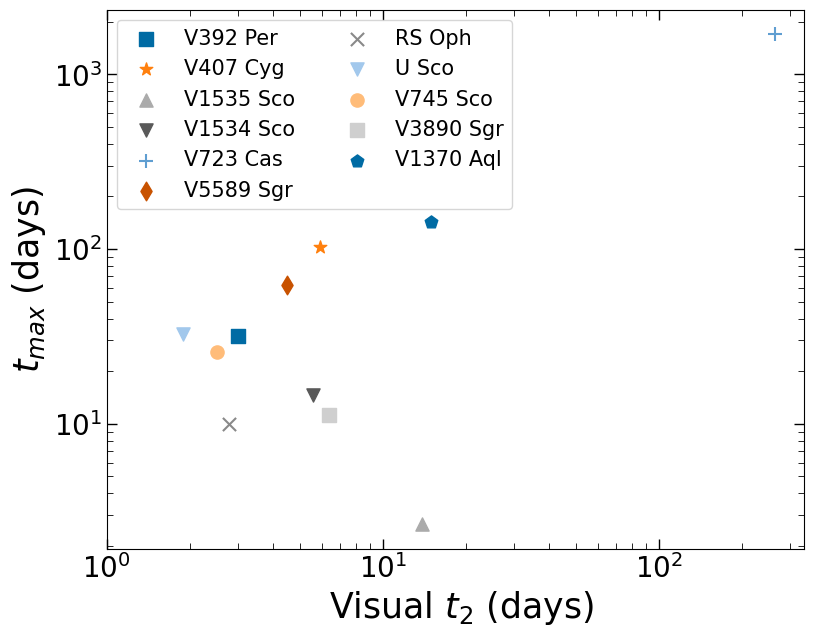

In [9]:
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots()
fig.set_size_inches(9,7)

#ax.plot(t2, poly(t2), color='black', linestyle=":", linewidth=2)


ax.scatter(t2[0], tmax[0], marker = 's', s=90, label="V392 Per")

ax.scatter(t2[1], tmax[1], marker = '*', s=90, label="V407 Cyg")
            
ax.scatter(t2[2],tmax[2], marker = '^', s=90, label="V1535 Sco")
            
ax.scatter(t2[3],tmax[3], marker = 'v', s=90, label="V1534 Sco")

ax.scatter(t2[4], tmax[4], marker = '+', s=90, label="V723 Cas")

ax.scatter(t2[5], tmax[5], marker = 'd', s=90, label="V5589 Sgr")

ax.scatter(t2[6], tmax[6], marker = 'x', s=90, label="RS Oph")

ax.scatter(t2[7], tmax[7], marker = 'v', s=90, label="U Sco")

ax.scatter(t2[8], tmax[8], marker = 'o', s=90, label="V745 Sco")

ax.scatter(t2[9], tmax[9], marker = 's', s=90, label="V3890 Sgr")

ax.scatter(t2[10], tmax[10], marker = 'p', s=90, label="V1370 Aql")


#ax.plot(t2, fit_model_weights(t2), linestyle=":")

ax.set_xscale('log')
ax.set_xticks([1,10,100], labels = [r'$10^{0}$',r'$10^1$', r'$10^2$'], fontsize = 20)

ax.set_yscale('log')
ax.set_yticks([ 10, 100, 1000], labels = [r'$10^1$', r'$10^2$', r'$10^3$'], fontsize = 20)

ax.set_xlabel(r" Visual $ t_{2} $ (days)", fontsize=25)
ax.set_ylabel(r"$ t_{max} $ (days)", fontsize=25)

ax.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

plt.legend(fontsize = 15, ncols=2)
plt.show()
fig.savefig("tmax_t2", dpi=300);

In [7]:
tmax = df['day when flux max (tmax)']
orbital_period = df["orbital period (hours)"]

In [8]:
orbital_period

0         81.9000
1     376938.0000
2        950.4000
3      12480.0000
4         16.6000
5         38.2000
6      10886.4000
7         29.5000
8       3276.0000
9      17942.4000
10        46.9944
Name: orbital period (hours), dtype: float64

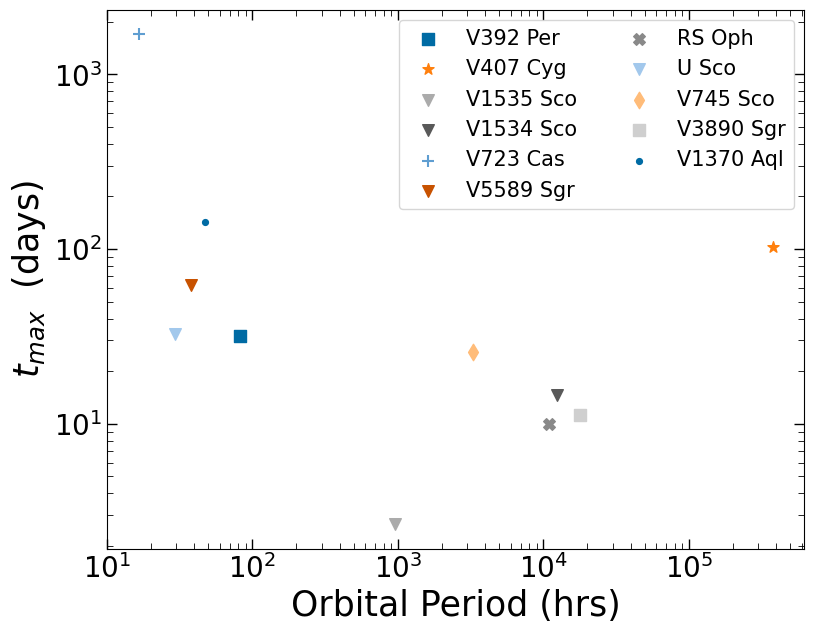

In [9]:
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots()
fig.set_size_inches(9,7)

ax.scatter(orbital_period[0], tmax[0], marker='s', s=70, label = 'V392 Per')

ax.scatter(orbital_period[1], tmax[1],  marker='*',s=70, label="V407 Cyg")

ax.scatter(orbital_period[2], tmax[2], marker='v', s=70, label="V1535 Sco")

ax.scatter(orbital_period[3], tmax[3], marker='v', s=70, label="V1534 Sco")            

ax.scatter(orbital_period[4], tmax[4],marker='+',s=70, label="V723 Cas")

ax.scatter(orbital_period[5], tmax[5], marker='v', s=70, label="V5589 Sgr")

ax.scatter(orbital_period[6], tmax[6], marker='X', s=70, label="RS Oph")

ax.scatter(orbital_period[7], tmax[7], marker='v',s=70, label="U Sco")

ax.scatter(orbital_period[8], tmax[8], marker='d', s=70, label="V745 Sco")

ax.scatter(orbital_period[9], tmax[9], marker='s', s=70, label="V3890 Sgr")

ax.scatter(orbital_period[10], tmax[10], marker='.', s=70, label="V1370 Aql")


ax.set_xscale('log')
ax.set_xticks([10, 100, 1000, 10000, 100000], labels = [r'$10^1$', r'$10^2$', r'$10^3$', r'$10^4$', r'$10^5$'], fontsize = 20)

ax.set_yscale('log')
ax.set_yticks([10, 100, 1000], labels = [r'$10^1$', r'$10^2$', r'$10^3$'], fontsize = 20)

ax.set_xlabel(" Orbital Period (hrs) ", fontsize=25)
ax.set_ylabel(r"$ t_{max} $  (days)", fontsize=25)

ax.tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

plt.legend(fontsize = 15, ncols=2)
plt.show()
fig.savefig("Tmax_orbital", dpi=300);

## Vpeak vs Smax

Plot showing the Flux (yaxis) at the highest peak, vs the Vpeak (x-axis)

(log on y axis, not on xaxis) (for 5 GHz frequency, (Vpeak has the mag going from gretest to lowest))


In [5]:
Vpeak = df['Vpeak (optical peak apparent mag)']

Smax = df['flux max (Smax)']
Smax_err = df["Smax error"]

In [9]:
np.array(Smax_err)

array([0.262, 0.901, 0.208, 0.665, 1.125, 0.173, 3.381, 0.029, 0.45 ,
       2.56 , 0.   ])

In [ ]:
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots()
fig.set_size_inches(9,7)


ax.errorbar(New_Vpeak[0], Smax[0], yerr=Smax_err[0], label="V392 Per", fmt='s',capsize=8, markersize=8)

ax.errorbar(New_Vpeak[1], Smax[1], yerr=Smax_err[1],label="V407 Cyg", fmt='*',capsize=8, markersize=8)

ax.errorbar(New_Vpeak[2], Smax[2], yerr=Smax_err[2], fmt='^', label="V1535 Sco", capsize=8, markersize=8)

ax.errorbar(New_Vpeak[3], Smax[3], yerr=Smax_err[3], fmt='v', label="V1534 Sco", capsize=8, markersize=8)            

ax.errorbar(New_Vpeak[4], Smax[4], yerr=Smax_err[4], label="V723 Cas", fmt='P',capsize=8, markersize=8)

ax.errorbar(New_Vpeak[5], Smax[5], yerr=Smax_err[5], label="V5589 Sgr", fmt='d', capsize=8, markersize=8)

ax.errorbar(New_Vpeak[6], Smax[6], yerr=Smax_err[6], label="RS Oph", fmt='X', capsize=8, markersize=8)

ax.errorbar(New_Vpeak[7], Smax[7], yerr=Smax_err[7], fmt='v', label="U Sco", capsize=8, markersize=8)

ax.errorbar(New_Vpeak[8], Smax[8], yerr=Smax_err[8], label="V745 Sco", fmt='8', capsize=8, markersize=8)

ax.errorbar(New_Vpeak[9], Smax[9], yerr=Smax_err[9], label="V3890 Sgr", fmt='s', capsize=8, markersize=8)

ax.errorbar(New_VV, Smax[10], xerr=new_err, yerr=Smax_err[10], label="V1370 Aql",fmt='.',capsize=8, markersize=8)


## orbital period vs radio peak

In [28]:
Smax = df['flux max (Smax)']
Smax_err = df["Smax error"]

orbital_period = df["orbital period (hours)"]

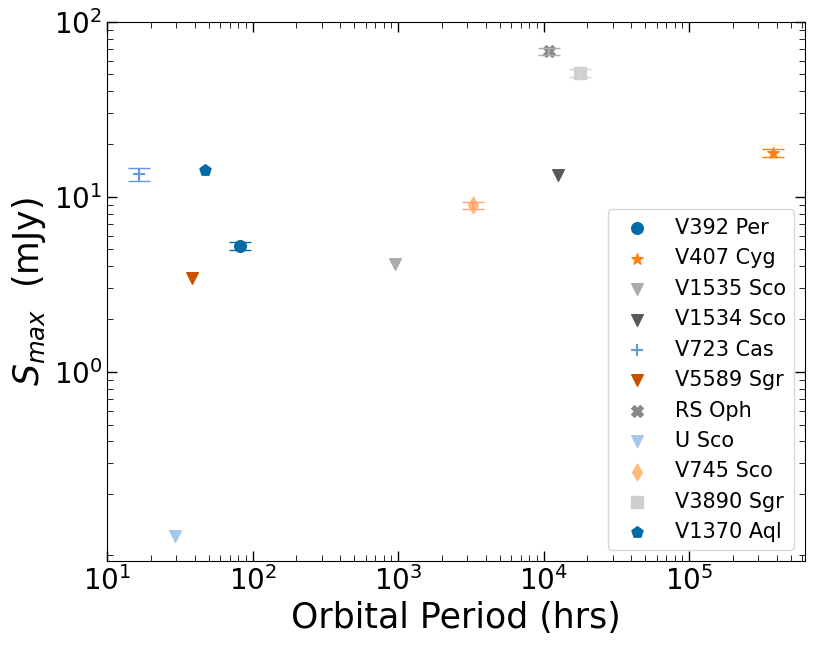

In [49]:
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots()
fig.set_size_inches(9,7)

ax.errorbar(orbital_period[0], Smax[0], yerr=Smax_err[0],capsize=8)
ax.scatter(orbital_period[0], Smax[0], marker='o', s=70, label = 'V392 Per')

ax.errorbar(orbital_period[1], Smax[1], yerr=Smax_err[1], capsize=8)
ax.scatter(orbital_period[1], Smax[1],  marker='*',s=70, label="V407 Cyg")

ax.scatter(orbital_period[2], Smax[2], marker='v', s=70, label="V1535 Sco")

ax.scatter(orbital_period[3], Smax[3], marker='v', s=70, label="V1534 Sco")            

ax.errorbar(orbital_period[4], Smax[4], yerr=Smax_err[4], color = 'cornflowerblue', capsize=8)
ax.scatter(orbital_period[4], Smax[4],marker='+',s=70, label="V723 Cas")

ax.scatter(orbital_period[5], Smax[5], marker='v', s=70, label="V5589 Sgr")

ax.errorbar(orbital_period[6], Smax[6], yerr=Smax_err[6], capsize=8)
ax.scatter(orbital_period[6], Smax[6], marker='X', s=70, label="RS Oph")

ax.scatter(orbital_period[7], Smax[7], marker='v',s=70, label="U Sco")

ax.errorbar(orbital_period[8], Smax[8], yerr=Smax_err[8], color = 'lightsalmon', capsize=8)
ax.scatter(orbital_period[8], Smax[8], marker='d', s=70, label="V745 Sco")

ax.errorbar(orbital_period[9], Smax[9], yerr=Smax_err[9], color='lightgray', capsize=8)
ax.scatter(orbital_period[9], Smax[9], marker='s', s=70, label="V3890 Sgr")

ax.scatter(orbital_period[10], Smax[10], marker='p', s=70, label="V1370 Aql")


ax.set_xscale('log')
ax.set_xticks([10, 100, 1000, 10000, 100000], labels = [r'$10^1$', r'$10^2$', r'$10^3$', r'$10^4$', r'$10^5$'], fontsize = 20)

ax.set_yscale('log')
ax.set_yticks([1, 10, 100], labels = [r'$10^{0}$', r'$10^1$', r'$10^2$'], fontsize = 20)

ax.set_xlabel(" Orbital Period (hrs) ", fontsize=25)
ax.set_ylabel(r"$ S_{max} $  (mJy)", fontsize=25)

ax.tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

plt.legend(fontsize = 15)
plt.show()
fig.savefig("Smax_orbital", dpi=300);

## Velocity and Tmax

In [46]:
velocity = df['velocity (km/s)']

tmax = df['day when flux max (tmax)']

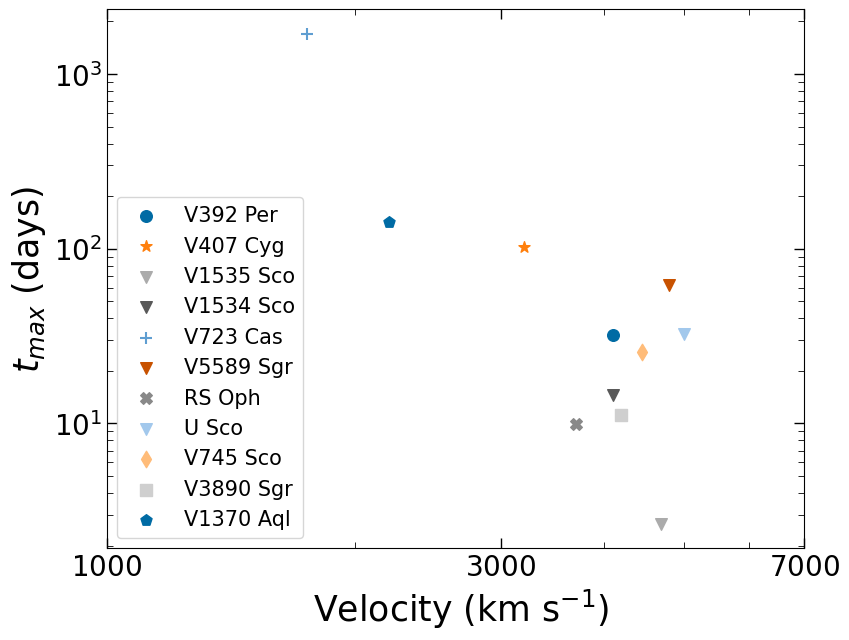

In [48]:
plt.style.use('tableau-colorblind10')

fig, ax = plt.subplots()
fig.set_size_inches(9,7)



ax.scatter(velocity[0], tmax[0], marker = 'o', s=70, label="V392 Per")

ax.scatter(velocity[1], tmax[1], marker = '*', s=70, label="V407 Cyg")
            
ax.scatter(velocity[2],tmax[2], marker = 'v', s=70, label="V1535 Sco")
            
ax.scatter(velocity[3],tmax[3], marker = 'v', s=70, label="V1534 Sco")

ax.scatter(velocity[4], tmax[4], marker = '+', s=70, label="V723 Cas")

ax.scatter(velocity[5], tmax[5], marker = 'v', s=70, label="V5589 Sgr")

ax.scatter(velocity[6], tmax[6], marker = 'X', s=70, label="RS Oph")

ax.scatter(velocity[7], tmax[7], marker = 'v', s=70, label="U Sco")

ax.scatter(velocity[8], tmax[8], marker = 'd', s=70, label="V745 Sco")

ax.scatter(velocity[9], tmax[9], marker = 's', s=70, label="V3890 Sgr")

ax.scatter(velocity[10], tmax[10], marker = 'p', s=70, label="V1370 Aql")


ax.set_xscale('log')
ax.set_xticks([1000,3000, 7000], labels = [ r'$1000$',r'$3000$' ,r'$7000$'], fontsize = 20)

ax.set_yscale('log')
ax.set_yticks([ 10, 100, 1000], labels = [r'$10^1$', r'$10^2$', r'$10^3$'], fontsize = 20)

ax.set_xlabel(r" Velocity (km s$^{-1})$", fontsize=25)
ax.set_ylabel(r"$ t_{max} $ (days)", fontsize=25)

ax.tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
ax.tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

plt.legend(fontsize = 15, loc='lower left')
plt.show()
fig.savefig("tmax_velocity", dpi=300);

0.8181818181818182